# 01 · Read the deposit before modelling it

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p03_ro_fouling/notebooks/01_read_the_deposit.ipynb)

**Project 3 — RO fouling and cleaning.** The question: *which RO train do we clean, in which week,
and why?* Before any model, this notebook downloads the one public plant record we have, checks it,
and finds out what its columns actually mean. Three of the findings change how everything later
reads the data.

**Data:** Su, Y.H., Meng, F.C. and Chang, P.Y. (2026) *Auditable clean-in-place decision support from routine SWRO SCADA.* Membranes 16(8), 257, [doi:10.3390/membranes16080257](https://doi.org/10.3390/membranes16080257). Deposit: [doi:10.5281/zenodo.21055948](https://doi.org/10.5281/zenodo.21055948), CC-BY-4.0. The plant and its owner are not named by the authors and are not named here.

Script version: `projects/p03_ro_fouling/step1_audit.py` · record: `VALIDATION.md`, sections 2–3.

In [1]:
# Setup. In Google Colab this installs the package from GitHub (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz]"
import os, subprocess, sys
REF = "main"        # before the Project 3 pull request is merged, use "p03-ro-fouling"
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    f"chemai[viz] @ git+https://github.com/EngMtaleb/chemai.git@{REF}"], check=True)
    os.environ["CHEMAI_DATA_DIR"] = "/content/data"     # where the deposit is downloaded

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
COL = {"A": "#2a6fb0", "B": "#128c84", "C": "#a8782f"}

## 0. Download, and refuse a file that is not the published one

`download_deposit` fetches the zip from Zenodo once and checks it against the md5 printed on the
record page. A different file is refused: an analysis built on a silently different file cannot be
reproduced by anyone else.

In [2]:
from chemai.config import RODepositConfig
from chemai.data.ro_deposit import (audit, cleaning_legs, download_deposit, duty_cycle, group_campaigns,
                                    load_daily, load_ledger, md5_of, recovery_by_campaign, split_cycles)

cfg = RODepositConfig()
folder = download_deposit(cfg=cfg)
print("published md5:", cfg.md5)
print("file md5     :", md5_of(folder / cfg.zip_name))

daily = load_daily(folder / cfg.daily_file)
ledger = load_ledger(folder / cfg.ledger_file)
print(f"{len(daily)} train-days, trains {sorted(daily['train'].unique())}, "
      f"days {daily['day_index'].min()}-{daily['day_index'].max()}")
daily.head()

published md5: 68b0223978f0e674d51cfc4c24e95435
file md5     : 68b0223978f0e674d51cfc4c24e95435
1340 train-days, trains ['A', 'B', 'C'], days 0-771


,train,day_index,n_10min_samples,basis,ndp_pct,dp_pct,flux_pct,sp_pct,days_since_cip,days_to_next_cip,state,dp_norm,censored,over_max
0,A,0,15,allrun,0.106845,0.000690,0.000000,0.000000,NaN,579.0,mid,1.000690,False,False
1,A,6,81,n3,0.000000,0.000000,0.014365,0.007832,NaN,573.0,mid,1.000000,True,False
2,A,7,33,n3,0.012029,0.000000,0.000000,0.000000,NaN,572.0,mid,1.000000,True,False
3,A,8,89,n3,0.007791,0.000000,0.000000,0.000000,NaN,571.0,mid,1.000000,True,False
4,A,9,72,n3,0.000000,0.861634,0.039128,0.002648,NaN,570.0,mid,1.861634,False,False


In [3]:
ledger      # the 18 cleaning campaigns: train, label, day, chemistry stage

,train,episode,day_index,stage
0,A,A#1,579,acid+alkaline
1,A,A#2,727,unspecified
2,A,A#3,765,unspecified
3,B,B#1,456,alkaline
4,B,B#2,482,alkaline
5,B,B#3,524,acid
6,B,B#4,544,acid
7,B,B#5,584,acid+alkaline
8,B,B#6,629,acid+alkaline
9,B,B#7,726,unspecified


## 1. Is `dp_pct` reset at every cleaning?

Three sources disagree. The deposit's column dictionary says all four indicators use a **fixed
commissioning baseline, never reset**. The article (and one deposited script) says `dp_pct` and
`ndp_pct` use **per-cleaning baselines**. The data decide: if an indicator is reset, it should fall
to about zero right after every cleaning.

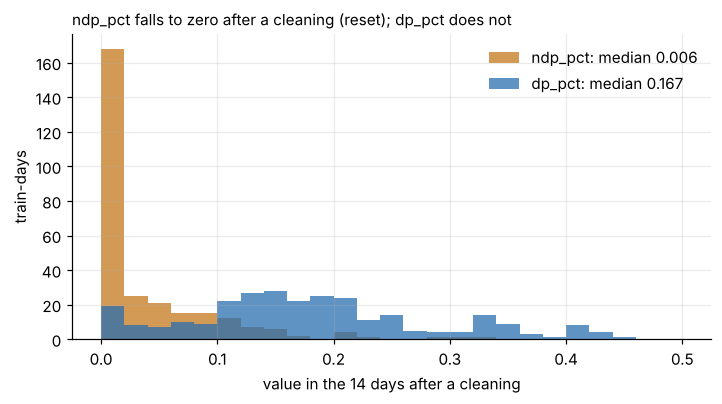

In [4]:
legs = cleaning_legs(daily)          # the cleaning days the table was built on
post = {"dp_pct": [], "ndp_pct": []}
for t, L in legs.items():
    g = daily[daily["train"] == t].set_index("day_index")
    for c in L:
        w = g[(g.index > c) & (g.index <= c + 14)]
        for k in post:
            post[k] += list(w[k])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(0, 0.5, 26)
for k, col in (("ndp_pct", "#c4791b"), ("dp_pct", "#2a6fb0")):
    ax.hist(post[k], bins=bins, alpha=0.75, color=col, label=f"{k}: median {np.median(post[k]):.3f}")
ax.set_xlabel("value in the 14 days after a cleaning"); ax.set_ylabel("train-days")
ax.set_title("ndp_pct falls to zero after a cleaning (reset); dp_pct does not", loc="left", fontsize=10)
ax.legend(frameon=False); plt.show()

**Finding 1.** `dp_pct` is **not** reset (it stays near its post-cleaning level, median about
0.17); `ndp_pct` **is**. So the pressure drop is read as **DP_norm = 1 + dp_pct**, on the fixed
baseline — and DP_norm 1.15 means "+15 % over start-up".

### A zero is not "clean"

Every indicator is clipped to [0, 1]. A zero means *at or below the baseline* — the true value is
unknown there. That is **censoring**, and the forecast must treat those days as upper bounds, not as
measurements.

In [5]:
zero_share = (daily[["dp_pct", "ndp_pct", "flux_pct", "sp_pct"]] == 0).mean().round(3)
print("share of train-days that are exactly zero:")
print(zero_share.to_string())
print("\nload_daily marks them:", daily["censored"].mean().round(3), "of DP_norm values are censored")

share of train-days that are exactly zero:
dp_pct      0.151
ndp_pct     0.363
flux_pct    0.669
sp_pct      0.283

load_daily marks them: 0.151 of DP_norm values are censored


## 2. Legs are not cleanings

An acid stage and an alkaline stage a few days apart are one cleaning **campaign**, but the table
marks them as two **legs**. Legs closer than 7 days are grouped.

In [6]:
camps = {t: group_campaigns(v, cfg.campaign_gap_days) for t, v in legs.items()}
print("legs      :", {t: len(v) for t, v in legs.items()}, "total", sum(len(v) for v in legs.values()))
print("campaigns :", {t: len(v) for t, v in camps.items()}, "total", sum(len(v) for v in camps.values()))
print("ledger    :", ledger.groupby("train").size().to_dict(), "total", len(ledger))

legs      : {'A': 3, 'B': 10, 'C': 10} total 23
campaigns : {'A': 3, 'B': 8, 'C': 7} total 18
ledger    : {'A': 3, 'B': 8, 'C': 7} total 18


**Finding 2.** 23 legs collapse into 18 campaigns, exactly the ledger's 18. The unit from here on
is the campaign.

## 3. Days that cannot exist

A 10-minute log holds at most 144 samples a day.

In [7]:
over = daily[daily["n_10min_samples"] > cfg.max_samples_per_day]
print(f"{len(over)} train-days on {over['day_index'].nunique()} plant days hold more than 144 samples "
      f"(up to {over['n_10min_samples'].max()})")
over[["train", "day_index", "n_10min_samples", "dp_pct"]].head(6)

18 train-days on 6 plant days hold more than 144 samples (up to 168)


,train,day_index,n_10min_samples,dp_pct
279,A,669,145,0.145553
284,A,674,151,0.159638
289,A,679,154,0.189257
290,A,680,168,0.174191
291,A,681,150,0.181237
292,A,682,162,0.180373


**Finding 3.** Six plant days hold up to 168 samples — duplicated or re-gridded records. Flagged,
not repaired; nothing later depends on them.

## 4. Do the published numbers reproduce?

The article reports that DP_norm falls after 16 of 17 evaluable cleanings, and how much of the
running time sits above 1.10, 1.15 and 1.20 (0.65, 0.47 and 0.30).

In [8]:
rec = recovery_by_campaign(daily, ledger)
ev = rec[rec["evaluable"]]
print(f"evaluable cleanings: {len(ev)}, DP_norm lower after: {(ev['drop'] > 0).sum()}")
for lvl, pub in ((1.10, 0.65), (1.15, 0.47), (1.20, 0.30)):
    print(f"share of running time at or above {lvl:.2f}: {duty_cycle(daily, lvl):.3f}   (published {pub})")

evaluable cleanings: 17, DP_norm lower after: 16
share of running time at or above 1.10: 0.672   (published 0.65)
share of running time at or above 1.15: 0.487   (published 0.47)
share of running time at or above 1.20: 0.313   (published 0.3)


Close, not identical — the article's exact daily basis is not deposited. Close enough to say we
read the same data the same way.

## 5. How much of the calendar is there?

In [9]:
a = audit(daily, ledger, cfg)
pd.DataFrame(a["trains"]).T[["rows", "coverage", "gaps_over_7", "longest_gap", "censored_share", "campaigns"]]

,rows,coverage,gaps_over_7,longest_gap,censored_share,campaigns
A,381.0,0.494,19.0,45.0,0.184,3.0
B,485.0,0.629,12.0,44.0,0.157,8.0
C,474.0,0.614,12.0,45.0,0.120,7.0


Half the calendar is missing for train A, and every train has gaps of six weeks. A method that
needs a continuous record fails here before it starts — so "too few recorded days" has to be an
answer of its own.

## 6. Cleaning cycles: the unit of every score

Days inside one cycle share a fouling layer, a cleaning and an operator's decision. They are not
independent samples, so every split and every score in this project is **by cycle**.

In [10]:
cycles = split_cycles(daily, cfg)
tab = pd.DataFrame([dict(cycle=c.id, kind=c.kind, length=c.length, days_recorded=c.n,
                         first=np.round(np.median(c.dp_norm[:5]), 3) if c.n else None,
                         last=np.round(np.median(c.dp_norm[-5:]), 3) if c.n else None) for c in cycles])
print(tab["kind"].value_counts().to_dict())
print("complete cycles, length in days: median", tab.loc[tab.kind == "complete", "length"].median())
tab

{'complete': 15, 'initial': 3, 'open': 3}
complete cycles, length in days: median 42.0


,cycle,kind,length,days_recorded,first,last
0,A:0-579,initial,579,190,1.000,1.213
1,A:579-727,complete,148,146,1.154,1.243
2,A:727-765,complete,38,36,1.190,1.210
3,A:765-772,open,7,6,1.152,1.159
4,B:1-456,initial,455,172,1.000,1.409
5,B:456-482,complete,26,25,1.336,1.408
6,B:482-524,complete,42,41,1.321,1.392
7,B:526-544,complete,18,17,1.220,1.209
8,B:545-584,complete,39,37,1.143,1.129
9,B:584-629,complete,45,44,1.079,1.034


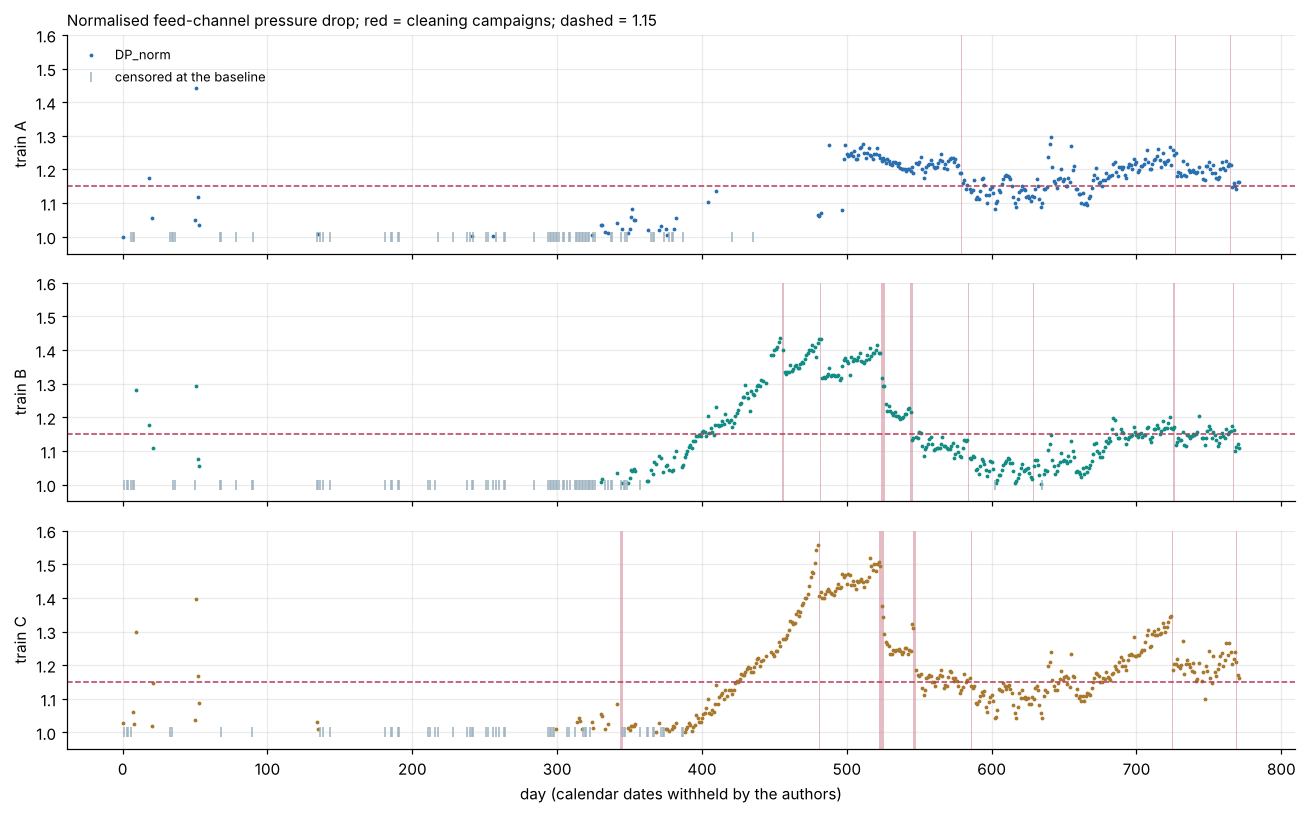

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, (t, g) in zip(axes, daily.groupby("train")):
    ok = ~g["censored"]
    ax.plot(g.loc[ok, "day_index"], g.loc[ok, "dp_norm"], ".", ms=3, color=COL[t], label="DP_norm")
    ax.plot(g.loc[~ok, "day_index"], g.loc[~ok, "dp_norm"], "|", ms=6, color="#9db3c0",
            label="censored at the baseline")
    for s, e in camps[t]:
        ax.axvspan(s - 0.5, e + 0.5, color="#b53c58", alpha=0.35, lw=0)
    ax.axhline(1.15, color="#b53c58", ls="--", lw=1)
    ax.set_ylabel(f"train {t}"); ax.set_ylim(0.95, 1.6)
axes[0].legend(loc="upper left", fontsize=8.5, frameon=False)
axes[0].set_title("Normalised feed-channel pressure drop; red = cleaning campaigns; dashed = 1.15",
                  loc="left", fontsize=10)
axes[-1].set_xlabel("day (calendar dates withheld by the authors)")
plt.tight_layout(); plt.show()

## What this notebook settled

- **DP_norm = 1 + `dp_pct`**, fixed baseline — the data overrule the article on this column.
- **A zero is censored**, not clean (15 % of DP_norm values).
- **18 campaigns, not 23 legs**; 15 complete cycles, median 42 days.
- **Gaps are large**: 49–63 % of days recorded.
- The published recovery (16 of 17) and threshold shares reproduce.

Next: [02 · The physics of the pressure drop](02_physics.ipynb).